<a href="https://colab.research.google.com/github/jayakrishnan004/SupervisedLearning_Casestudy/blob/main/SupervisedLearningCaseStudy_Jayakrishnan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Study: Customer Churn Prediction**

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# **1. Exploratory Data Analysis (EDA):**

# Perform a detailed exploratory data analysis to understand the distribution of each feature and its relationship with the target variable, Churn.

In [86]:
train_df = pd.read_csv("/content/drive/MyDrive/DSA - ICTAK/DATASETS/Supervised learning : customer churn analysis/Training_data.csv")
test_df = pd.read_csv("/content/drive/MyDrive/DSA - ICTAK/DATASETS/Supervised learning : customer churn analysis/Testing_data.csv")

**ANALYSIS**

In [87]:
train_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [88]:
train_df.shape

(5634, 21)

In [89]:
# Understand column names and data types
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5465 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5465 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [90]:
# Statistical summary
train_df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,5634,5465,5634.000000,5634,5634,5634.000000,5634,5634,5634,5465,...,5634,5634,5634,5634,5634,5634,5634,5240.000000,5353,5634
unique,5634,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,5040,2
top,9509-MPYOD,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,2744,NaN,2890,3960,NaN,5081,2701,2486,2720,...,2485,2782,2244,2232,3094,3350,1892,NaN,9,4130
mean,NaN,NaN,0.159744,NaN,NaN,32.606851,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.102052,NaN,NaN
std,NaN,NaN,0.366401,NaN,NaN,24.614976,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.056443,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.800000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.650000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,56.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.050000,NaN,NaN


In [91]:
train_df['Churn'].value_counts()

,count
Churn,
No,4130
Yes,1504


In [92]:
train_df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.304934
Yes,26.695066


In [93]:
test_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6080-TCMYC,Male,0,Yes,Yes,40,Yes,Yes,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,81.20,3292.3,No
1,7285-KLOTR,Female,0,Yes,No,12,Yes,Yes,DSL,Yes,...,Yes,No,Yes,Yes,One year,No,Electronic check,78.85,876.75,No
2,7486-KSRVI,Male,0,No,No,43,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Yes,One year,Yes,Electronic check,100.00,4211.55,Yes
3,9924-JPRMC,Male,0,No,No,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,118.20,8547.15,No
4,4439-YRNVD,Female,0,No,No,10,No,No phone service,DSL,No,...,No,Yes,No,No,Month-to-month,No,Electronic check,36.25,374,No


In [94]:
test_df.shape

(1409, 21)

In [95]:
train_df.duplicated().sum()

np.int64(0)




Both datasets contain the same columns, including the target variable Churn

customerID is an identifier, not a meaningful customer behavior feature. We will generally exclude it from model training.

TotalCharges is currently an object datatype. We should convert it for EDA, treating blank strings as missing values.

In [96]:
# errors='coerce' converts invalid values, including blank strings, into NaN.
# This is a temporary cleaning step for analysis; we'll decide the final missing-value treatment during preprocessing.
train_df["TotalCharges"] = pd.to_numeric(train_df["TotalCharges"], errors="coerce")
test_df["TotalCharges"] = pd.to_numeric(test_df["TotalCharges"], errors="coerce")

In [97]:
# Checks missing values.
train_df.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [98]:
# Checks the peercentage.
(train_df.isnull().sum() / len(train_df)) * 100

,0
customerID,0.000000
gender,2.999645
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,2.999645


Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')
PLOT of Numerical Columns


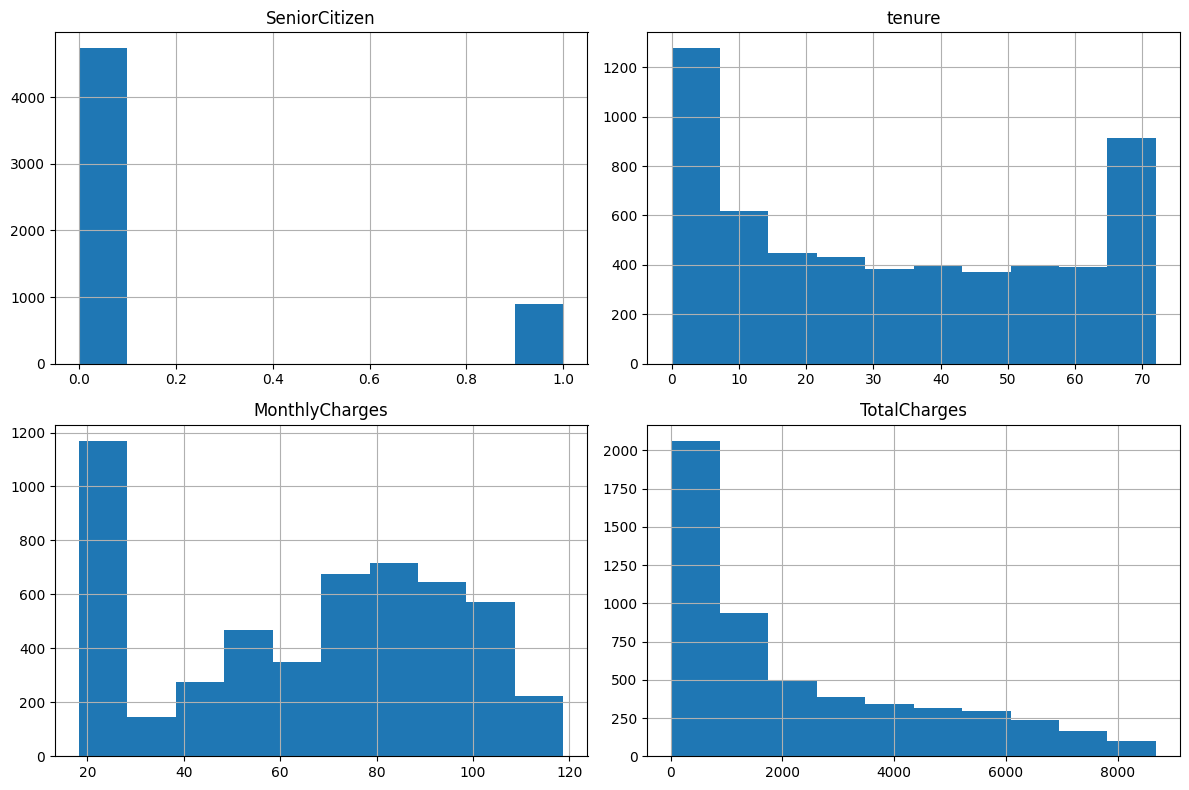

In [99]:
# Identify numerical columns.
print(train_df.select_dtypes(include=np.number).columns)

# Plot the distributions of the numerical columns.
print("PLOT of Numerical Columns")
train_df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [100]:
categorical_cols = train_df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(train_df[col].value_counts())


customerID
customerID
9509-MPYOD    1
7746-AWNQW    1
2208-UGTGR    1
4884-LEVMQ    1
6682-VCIXC    1
             ..
5649-RXQTV    1
3908-MKIMJ    1
4277-BWBML    1
9110-HSGTV    1
3402-XRIUO    1
Name: count, Length: 5634, dtype: int64

gender
gender
Male      2744
Female    2721
Name: count, dtype: int64

Partner
Partner
No     2890
Yes    2744
Name: count, dtype: int64

Dependents
Dependents
No     3960
Yes    1674
Name: count, dtype: int64

PhoneService
PhoneService
Yes    5081
No      553
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  2701
Yes                 2380
No phone service     553
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    2486
DSL            1945
No             1203
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     2720
Yes                    1574
No internet service    1171
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     2459
Yes                    1972


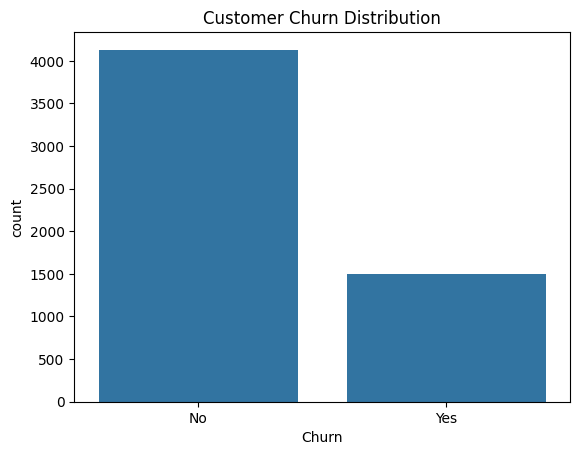

In [101]:
# Identify class imbalance between customers who churned and those who stayed.
sb.countplot(data=train_df, x='Churn')
plt.title('Customer Churn Distribution')
plt.show()

**Analyze numerical features against Churn**

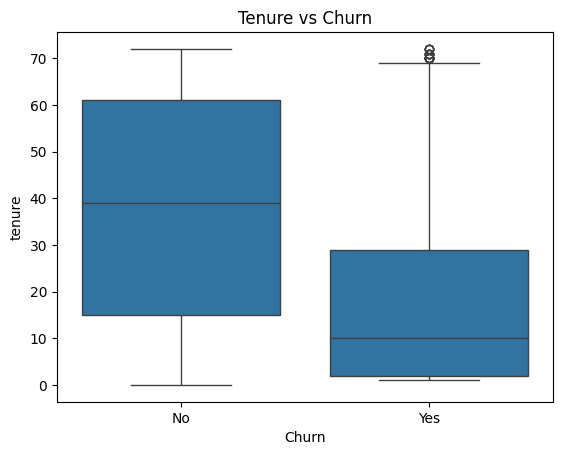

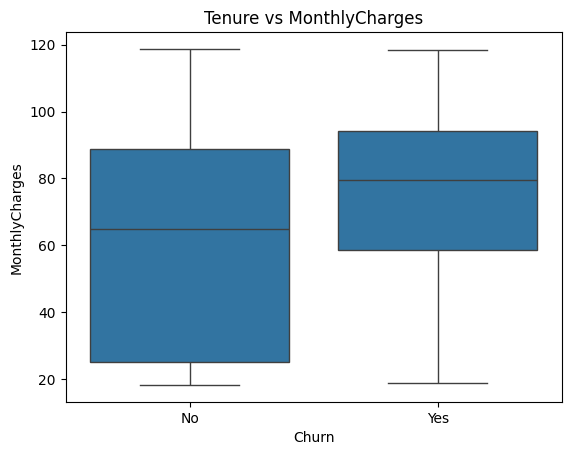

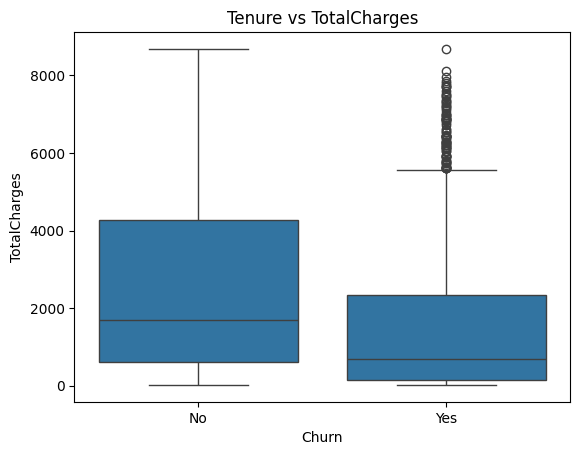

In [102]:

sb.boxplot(data=train_df, x='Churn', y='tenure')
plt.title('Tenure vs Churn')
plt.show()

sb.boxplot(data=train_df, x='Churn', y='MonthlyCharges')
plt.title('Tenure vs MonthlyCharges')
plt.show()

sb.boxplot(data=train_df, x='Churn', y='TotalCharges')
plt.title('Tenure vs TotalCharges')
plt.show()



**Analyze categorical features against Churn**

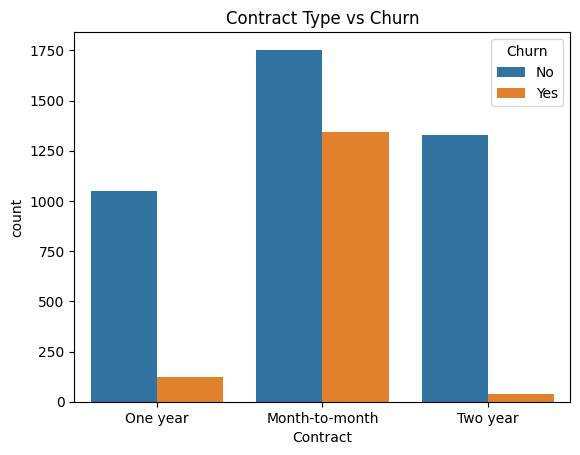

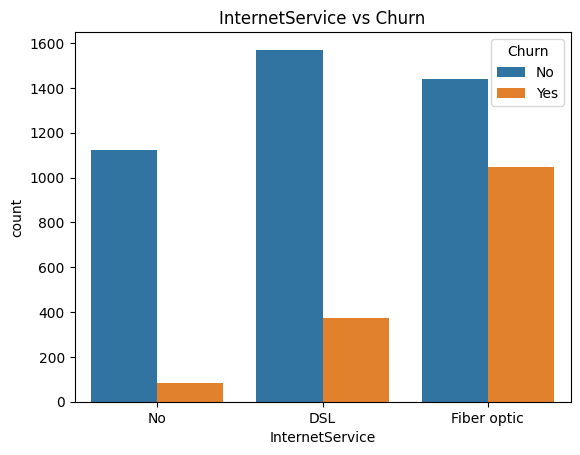

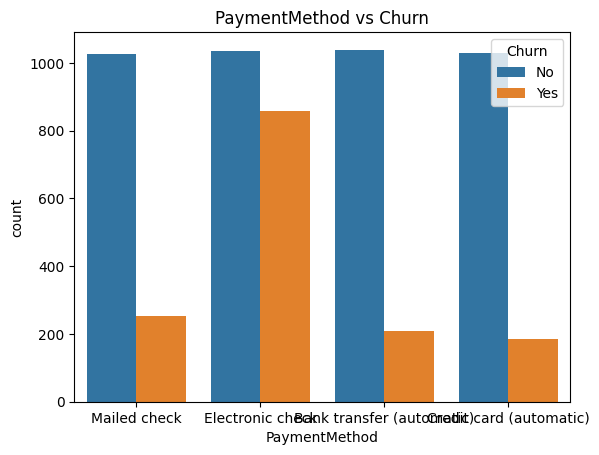

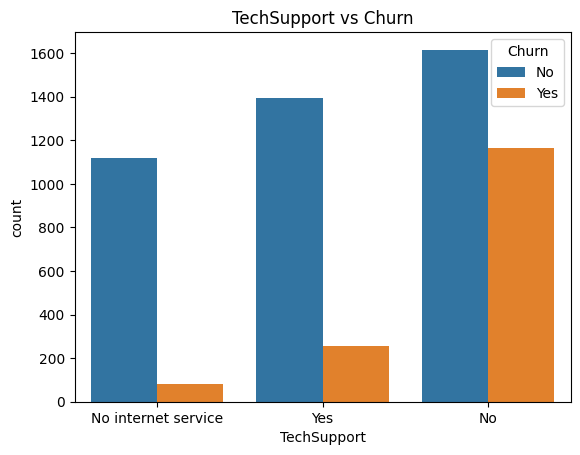

In [103]:
sb.countplot(data=train_df, x='Contract', hue='Churn')
plt.title('Contract Type vs Churn')
plt.show()

sb.countplot(data=train_df, x='InternetService', hue='Churn')
plt.title('InternetService vs Churn')
plt.show()

sb.countplot(data=train_df, x='PaymentMethod', hue='Churn')
plt.title('PaymentMethod vs Churn')
plt.show()

sb.countplot(data=train_df, x='TechSupport', hue='Churn')
plt.title('TechSupport vs Churn')
plt.show()

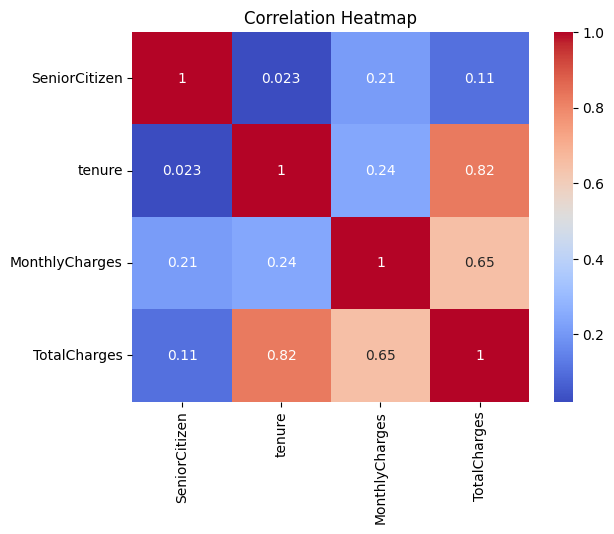

In [104]:
# Correlation analysis
numeric_df = train_df.select_dtypes(include=np.number)

sb.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

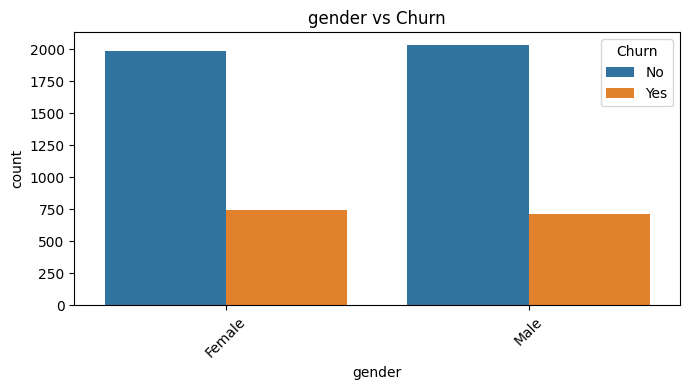

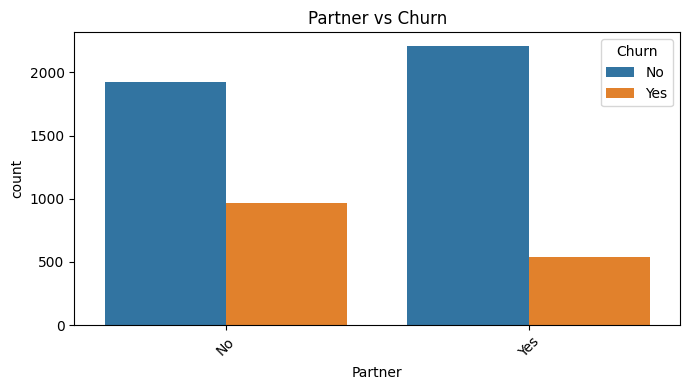

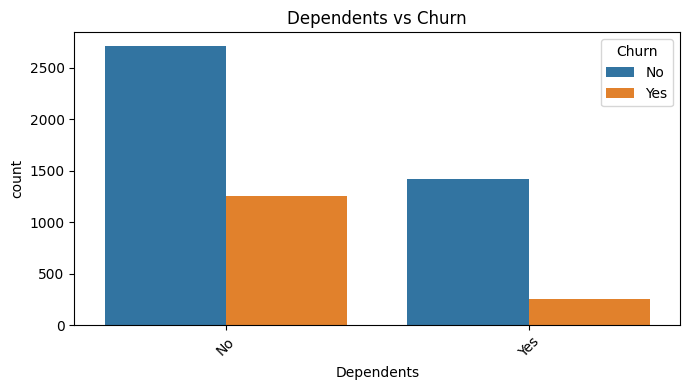

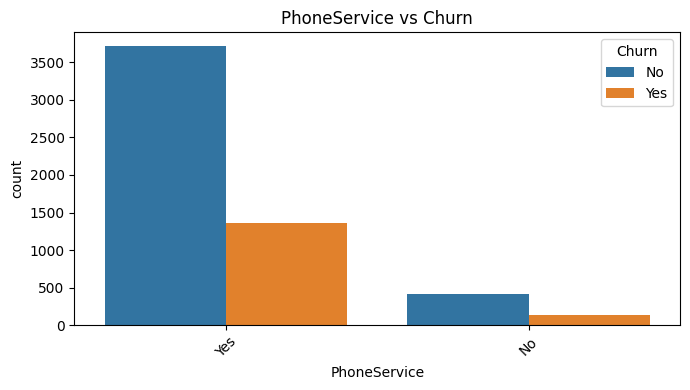

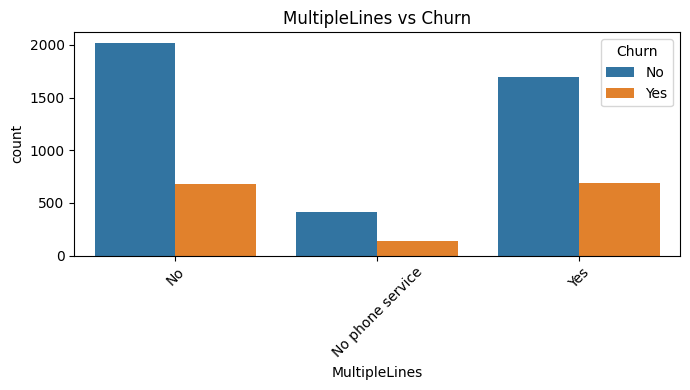

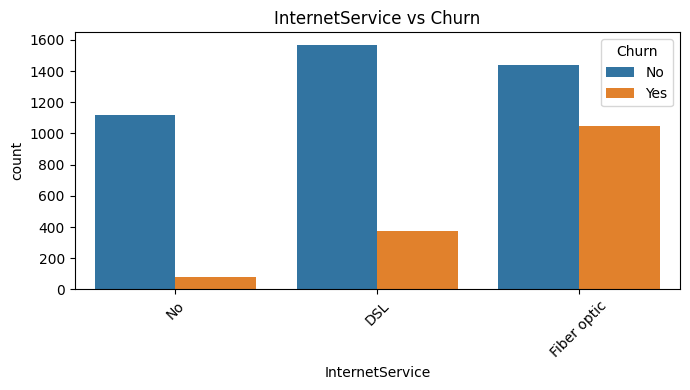

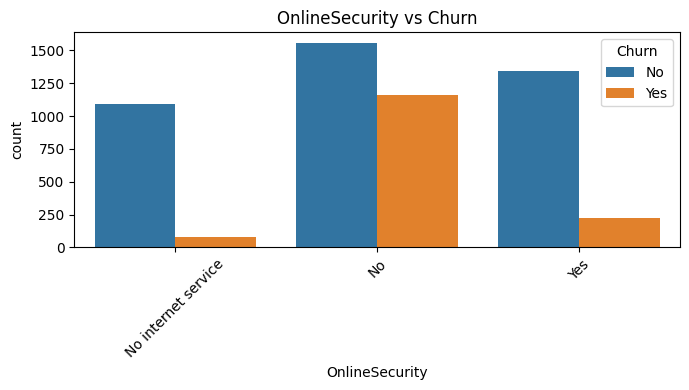

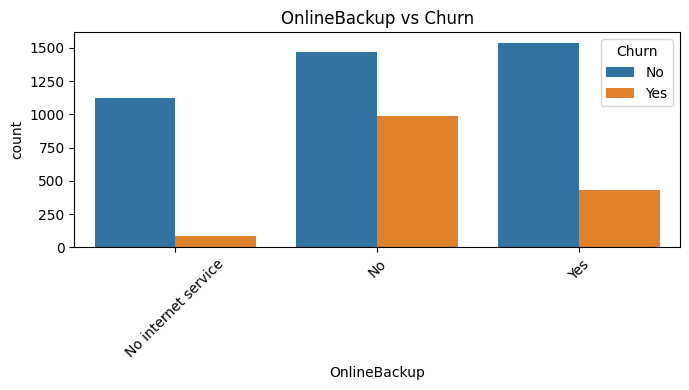

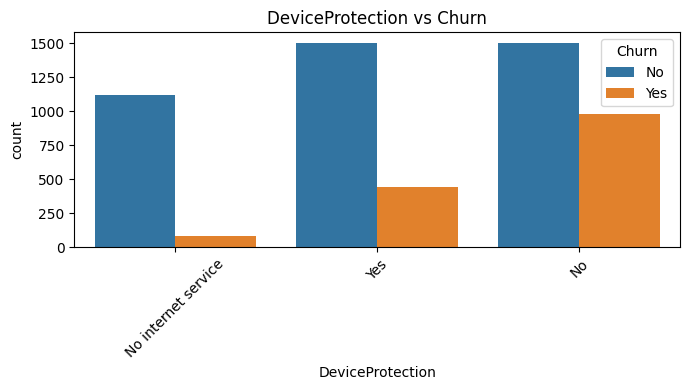

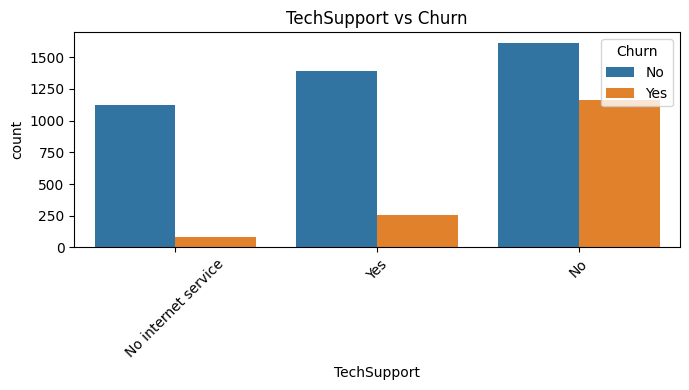

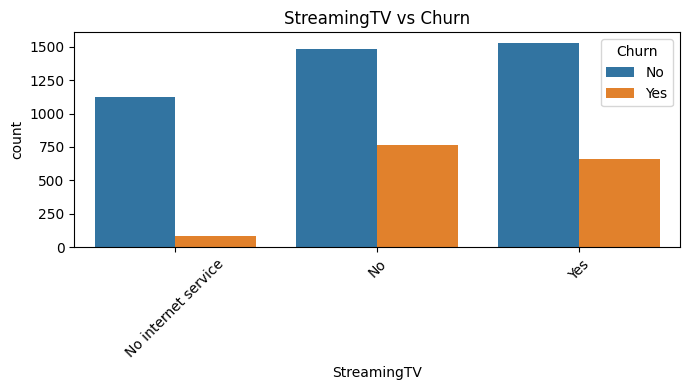

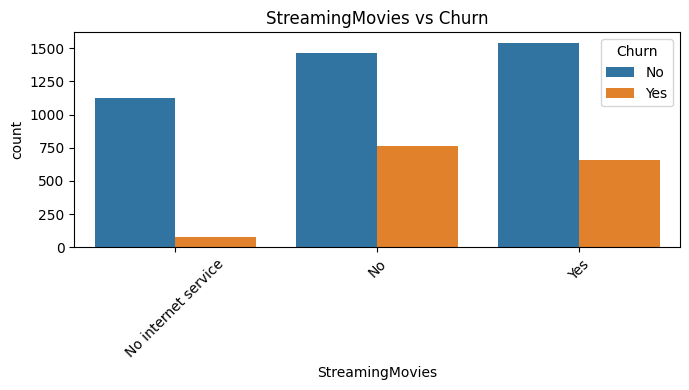

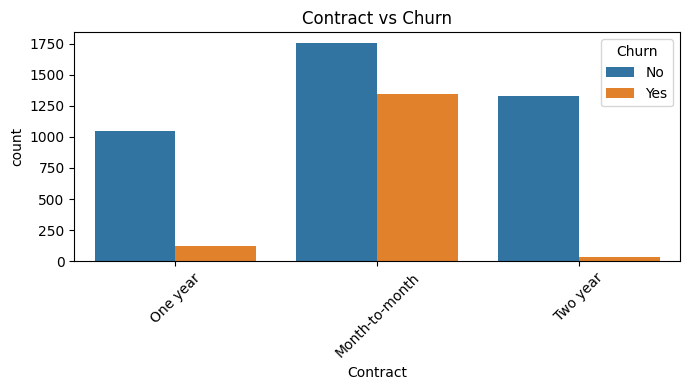

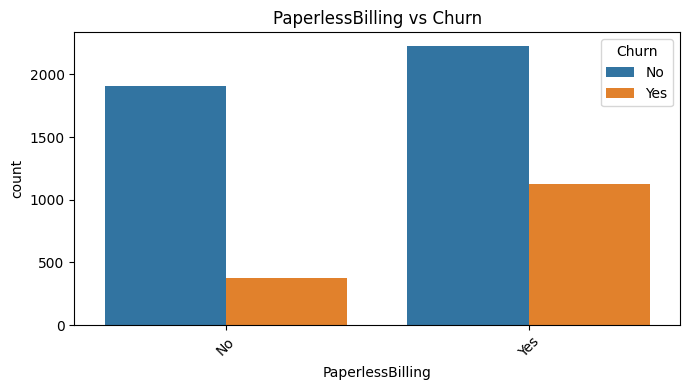

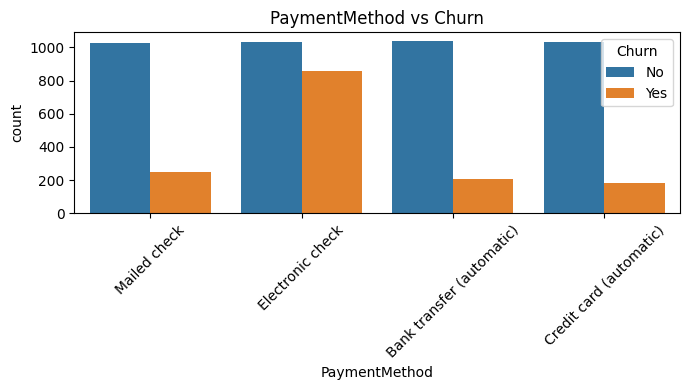

In [105]:
# Compare all the categorical features with churn using loop.
categorical_cols = [
    col for col in train_df.select_dtypes(include='object').columns
    if col not in ['customerID', 'Churn']
]

for col in categorical_cols:
    plt.figure(figsize=(7, 4))

    sb.countplot(data=train_df, x=col, hue='Churn')

    plt.title(f'{col} vs Churn')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# **2. Data Preprocessing**

In [106]:
train_df.isnull()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5630,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5631,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5632,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [107]:
train_df.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [108]:
# Replace the missing values using filna
# for categorical columns - use mode
# for numerical columns - use median

# Categorical columns
train_df['gender'] = train_df['gender'].fillna(train_df['gender'].mode()[0])

train_df['OnlineSecurity'] = train_df['OnlineSecurity'].fillna(
    train_df['OnlineSecurity'].mode()[0])

# Numerical column
train_df['MonthlyCharges'] = train_df['MonthlyCharges'].fillna(
    train_df['MonthlyCharges'].median())

In [109]:
# customers with zero tenure may legitimately have zero total charges.
# check whether TotalCharges missing values are associated with customers having zero tenure.
train_df.loc[
    (train_df['TotalCharges'].isnull()) &
    (train_df['tenure']==0),
    ["tenure","TotalCharges"]
]

,tenure,TotalCharges
1120,0,NaN
1284,0,NaN
1347,0,NaN
3116,0,NaN
3575,0,NaN
4163,0,NaN
4323,0,NaN
4391,0,NaN
5212,0,NaN


In [110]:
# change the value of Totalcharges = Nan to Zero if the tenure = 0
# if tenure not zero and TotalCharges is Nan, use median to replace.


# Customers with zero tenure
train_df.loc[
    (train_df['TotalCharges'].isnull()) & (train_df['tenure'] == 0),
    'TotalCharges'
] = 0

# Customers with non-zero tenure
train_df['TotalCharges'] = train_df['TotalCharges'].fillna(
    train_df['TotalCharges'].median()
)

**Categorical Encoding**

Label Encoding: Assigns numerical values to categories.



One-Hot Encoding: Creates separate binary columns for each category.

In [111]:
# Identify categorical columns.
categorical_cols = train_df.select_dtypes(include='object').columns.tolist()



# Exclude
# customerID: Unique identifier; it doesn't provide useful predictive information.
# Churn: This is our target variable, which we want to predict. It must not be included as an input feature.

categorical_cols.remove('customerID')
categorical_cols.remove('Churn')

print(categorical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


**One-Hot Encoding**

use get_dummies() to understand how One-Hot Encoding works

Converts each categorical feature into separate binary columns.

1 means the category is present.

0 means the category is absent.

Keeps numerical columns unchanged.

In [112]:
train_encoded = pd.get_dummies(
    train_df,
    columns=categorical_cols,
    dtype=int
)

print(train_encoded.shape)
print("\  n","\n")
print(train_encoded.head())

(5634, 47)
\  n 

   customerID  SeniorCitizen  tenure  MonthlyCharges  TotalCharges Churn  \
0  9509-MPYOD              0      35           20.75        700.45    No   
1  7746-AWNQW              0      28           35.75        961.40    No   
2  2208-UGTGR              0      56           98.60       5581.05    No   
3  4884-LEVMQ              0      39           20.45        790.00    No   
4  6682-VCIXC              0      43           51.25       2151.60    No   

   gender_Female  gender_Male  Partner_No  Partner_Yes  ...  \
0              1            0           1            0  ...   
1              1            0           1            0  ...   
2              0            1           1            0  ...   
3              0            1           0            1  ...   
4              1            0           0            1  ...   

   StreamingMovies_Yes  Contract_Month-to-month  Contract_One year  \
0                    0                        0                  1   
1     

<>:8: SyntaxWarning: invalid escape sequence '\ '
<>:8: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1968/710357109.py:8: SyntaxWarning: invalid escape sequence '\ '
  print("\  n","\n")


In [113]:
# scale the numerical columns in a separate DataFrame.
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

train_scaled = train_df.copy()

train_scaled[numerical_cols] = scaler.fit_transform(
    train_scaled[numerical_cols]
)

train_scaled[numerical_cols].head()

,tenure,MonthlyCharges,TotalCharges
0,0.097232,-1.541793,-0.692296
1,-0.187173,-1.024876,-0.574631
2,0.950447,1.141008,1.508416
3,0.259749,-1.552131,-0.651917
4,0.422266,-0.490728,-0.037958


In [114]:
# Outlier Handling
# IQR

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numerical_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train_df[
        (train_df[col] < lower) | (train_df[col] > upper)
    ]

    print(f'{col}: {len(outliers)} outliers')

tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 23 outliers


In [115]:
Q1 = train_df['TotalCharges'].quantile(0.25)
Q3 = train_df['TotalCharges'].quantile(0.75)
IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR

outliers = train_df[train_df['TotalCharges'] > upper]

outliers[['tenure', 'MonthlyCharges', 'TotalCharges']].head(10)

,tenure,MonthlyCharges,TotalCharges
93,72,115.15,8349.45
111,72,114.90,8496.70
269,72,115.80,8476.50
724,72,114.85,8317.95
901,72,115.80,8332.15
1666,72,116.05,8404.90
1865,72,115.50,8425.15
1959,72,117.50,8670.10
2085,72,117.80,8684.80
2767,72,114.05,8468.20


From the above data:

Decision: Retain all 23 outliers.

Reason:
- The values are within a plausible business range.
- They are consistent with long customer tenure and monthly charges.
- Removing them would result in losing valid customer information.

The IQR method identified 23 potential outliers in TotalCharges. Upon inspection, these observations corresponded to customers with long tenure and higher monthly charges. Since the values were plausible and represented genuine customer behaviour, no outlier removal or transformation was performed.

# **3. Feature Engineering**

Feature engineering means creating new features from existing columns to help the machine learning model identify useful patterns.

In [116]:
# Step 1: Create a Customer Lifetime Value feature
# CLV = Tenure * MonthlyCharges

train_df['CustomerLifetimeValue'] = train_df['tenure'] * train_df['MonthlyCharges']

train_df[['tenure', 'MonthlyCharges', 'CustomerLifetimeValue']].head()

,tenure,MonthlyCharges,CustomerLifetimeValue
0,35,20.75,726.25
1,28,35.75,1001.00
2,56,98.60,5521.60
3,39,20.45,797.55
4,43,51.25,2203.75


In [117]:
# Step 2: Create an interaction feature – Tenure and Contract
train_df['Tenure_Contract'] = (
    train_df['tenure'].astype(str) + '_' + train_df['Contract']
)

In [118]:
train_df[['CustomerLifetimeValue', 'Tenure_Contract']].head()

,CustomerLifetimeValue,Tenure_Contract
0,726.25,35_One year
1,1001.00,28_Month-to-month
2,5521.60,56_Month-to-month
3,797.55,39_Two year
4,2203.75,43_One year


**FEATURE SELECTION**



In [119]:
# Separate features and target
X = train_df.drop(columns=['customerID', 'Churn'])
y = train_df['Churn'].map({'No': 0, 'Yes': 1})

# Encode categorical features
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [120]:
# Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

                             Feature  Importance
3                       TotalCharges    0.116522
4              CustomerLifetimeValue    0.113608
2                     MonthlyCharges    0.099633
1                             tenure    0.082340
11       InternetService_Fiber optic    0.037167
26                 Contract_Two year    0.029780
29    PaymentMethod_Electronic check    0.029578
14                OnlineSecurity_Yes    0.022765
5                        gender_Male    0.022679
27              PaperlessBilling_Yes    0.022323
20                   TechSupport_Yes    0.020044
61  Tenure_Contract_1_Month-to-month    0.019494
6                        Partner_Yes    0.018357
16                  OnlineBackup_Yes    0.018218
25                 Contract_One year    0.018101


TotalCharges, CustomerLifetimeValue, MonthlyCharges and tenure were identified as the most important features. Contract type, payment method and internet service also contributed to the prediction. The newly engineered features were included for further model evaluation. No features were removed at this stage because their usefulness will be assessed through model performance.

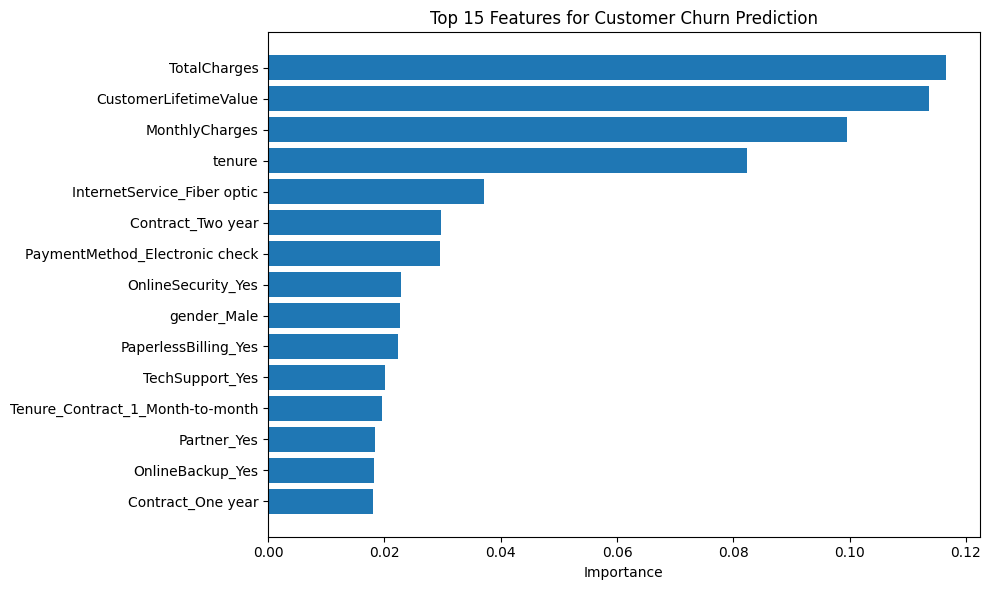

In [121]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('Top 15 Features for Customer Churn Prediction')
plt.tight_layout()
plt.show()

#**4. Model Development**
use:
1. Logistic Regression – a classification algorithm that predicts the probability of churn.
2. Decision Tree – makes predictions using a series of decision rules.
3. Random Forest – combines multiple decision trees to improve prediction.

In [122]:
train_raw = pd.read_csv("/content/drive/MyDrive/DSA - ICTAK/DATASETS/Supervised learning : customer churn analysis/Training_data.csv")
test_raw = pd.read_csv("/content/drive/MyDrive/DSA - ICTAK/DATASETS/Supervised learning : customer churn analysis/Testing_data.csv")

In [123]:
# Convert blank strings into missing values and ensure TotalCharges is numerical
for df in [train_raw, test_raw]:
    df.replace(r'^\s*$', np.nan, regex=True, inplace=True)
    df['TotalCharges'] = pd.to_numeric(
        df['TotalCharges'], errors='coerce'
    )

Create the two engineered features in both datasets.

We need the same features in both datasets because the model will expect the same input columns.

In [124]:
for df in [train_raw, test_raw]:
    df['CustomerLifetimeValue'] = (
        df['tenure'] * df['MonthlyCharges']
    )

    df['Tenure_Contract'] = (
        df['tenure'].astype(str) + '_' + df['Contract']
    )

In [125]:
# Separate features and target
X = train_raw.drop(columns=['customerID', 'Churn'])
y = train_raw['Churn'].map({'No': 0, 'Yes': 1})

In [126]:
# Split the dataset - 80% for training and 20% for validation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [127]:
# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical:", numerical_cols)
print("Categorical:", categorical_cols)

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'CustomerLifetimeValue']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_Contract']


**Create the preprocessing pipeline.**

Numerical missing values → Median imputation.



Categorical missing values → Mode imputation.



Numerical features → StandardScaler.



Categorical features → One-Hot Encoding.



In [128]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


# SimpleImputer(strategy='most_frequent') → fills missing categorical values using mode.
# OneHotEncoder() → converts categorical values into numerical columns.

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

Our preprocessing pipeline performs four operations:

Numerical columns
1. Fill missing values using the median.
2. Apply StandardScaler.

Categorical columns
1. Fill missing values using the mode.
2. Apply One-Hot Encoding.

In [129]:
print("Training:", X_train.shape)
print("Validation:", X_test.shape)
print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Training: (4507, 21)
Validation: (1127, 21)
Numerical columns: 5
Categorical columns: 16


# **Logistic Regression**

Logistic Regression is a supervised classification algorithm. It predicts the probability of a customer belonging to a particular class.

In our project:
- 0 = Customer will not churn.
- 1 = Customer will churn.

In [130]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

logistic_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

# preprocessor performs encoding, imputation and scaling.
# LogisticRegression learns patterns from the processed data.
# fit() trains the model.


# Prediction
y_pred_lr = logistic_model.predict(X_test)

In [131]:
# EVALUATION
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\n")
print("ROC-AUC Score:")
print(roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]))

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87       826
           1       0.65      0.56      0.60       301

    accuracy                           0.80      1127
   macro avg       0.75      0.72      0.73      1127
weighted avg       0.79      0.80      0.80      1127

Confusion Matrix:
[[735  91]
 [133 168]]


ROC-AUC Score:
0.8439141521803835


Result:

Class 0 – No Churn
- Precision: 85% of customers predicted as non-churners actually stayed.
- Recall: The model correctly identified 89% of actual non-churners.

Class 1 – Churn
- Precision: 65% of customers predicted as churners actually churned.
- Recall: The model identified only 56% of actual churners.
- F1-score: 0.60, indicating room for improvement.

Confusion matrix:

TN = 735: Correctly predicted customers who stayed.



FP = 91: Predicted churn, but customers actually stayed.



FN = 133: Failed to identify customers who actually churned.



TP = 168: Correctly predicted customers who churned.

Your ROC-AUC score is approximately 84.39%.

ROC-AUC measures how well the model distinguishes between the two classes across different classification thresholds.

A score closer to 1 indicates better class discrimination.

# **Decision Tree Classifier**

A Decision Tree makes predictions by splitting data based on feature conditions.

In [132]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_model.fit(X_train, y_train)


# Prediction
y_pred_dt = dt_model.predict(X_test)

In [133]:
# EVALUATION
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("ROC-AUC Score:")
print(roc_auc_score(
    y_test,
    dt_model.predict_proba(X_test)[:, 1]
))

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       826
           1       0.52      0.53      0.53       301

    accuracy                           0.75      1127
   macro avg       0.68      0.68      0.68      1127
weighted avg       0.75      0.75      0.75      1127

Confusion Matrix:
[[682 144]
 [142 159]]
ROC-AUC Score:
0.6804960060492466


Confusion Matrix

- TN = 682: Correctly predicted non-churners.
- FP = 144: Predicted churn, but customers stayed.
- FN = 142: Failed to identify actual churners.
- TP = 159: Correctly identified churners.


ROC-AUC: 0.6805

The model is not distinguishing churners from non-churners as effectively as Logistic Regression.

# **Random Forest Classifier**

In [134]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])
# n_estimators=100 - Random Forest contains 100 Decision Trees.
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [135]:
# EVALUATION
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("ROC-AUC Score:")
print(roc_auc_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
))

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87       826
           1       0.67      0.51      0.58       301

    accuracy                           0.80      1127
   macro avg       0.75      0.71      0.73      1127
weighted avg       0.79      0.80      0.79      1127

Confusion Matrix:
[[749  77]
 [146 155]]
ROC-AUC Score:
0.8347437516591186


Confusion matrix
- TN = 749: Correctly predicted non-churners.
- FP = 77: Predicted churn, but customers stayed.
- FN = 146: Failed to identify actual churners.
- TP = 155: Correctly identified churners.

ROC-AUC: 0.8347

Random Forest has the highest churn precision among our three models, but its churn recall is relatively low.

**CONCLUSION**

Three machine learning algorithms, Logistic Regression, Decision Tree and Random Forest, were trained and evaluated for customer churn prediction. Logistic Regression achieved the best overall performance, with 80% accuracy and an ROC-AUC score of 0.844. It also achieved the highest recall and F1-score for the churn class. Random Forest achieved similar accuracy but had lower churn recall, while Decision Tree showed comparatively weaker performance. Therefore, Logistic Regression was selected as the best-performing model based on the validation results.

# **Model Fine-Tuning:**

Select Logistic Regression based on its current validation performance.



Apply GridSearchCV to find better hyperparameters.



Evaluate the tuned model on the validation dataset.



Compare the tuned results against the original Logistic Regression results.



Finally, evaluate the selected model using the provided testing CSV.

Hyperparameter tuning will use cross-validation on X_train and y_train

GridSearchCV automatically tests different hyperparameter combinations and identifies the best combination using cross-validation.



In [136]:
from sklearn.model_selection import GridSearchCV


In [137]:
parameter_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced'],
    'classifier__solver': ['liblinear', 'lbfgs']
}

C	Controls regularization strength.

class_weight	Gives different importance to different classes. balanced adjusts weights according to class frequencies.

solver	Specifies the optimization algorithm used to train Logistic Regression.

classifier__ prefix refers to the classifier step inside our existing ML pipeline.

In [138]:
grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=parameter_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# cv=5: Divides the training data into five folds for cross-validation.
# scoring='f1': Selects the combination with the highest average F1-score.
# n_jobs=-1: Uses all available CPU cores.


# Display the best parameters.
print("Best Parameters:", grid_search.best_params_)

print("Best Cross-Validation F1 Score:", grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}
Best Cross-Validation F1 Score: 0.6420170787534035


**Evaluate the tuned model.**

In [139]:

best_model = grid_search.best_estimator_
# Make Predictions.
y_pred_tuned = best_model.predict(X_test)
# EVALUATION
print("Classification Report:")
print(classification_report(y_test, y_pred_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("ROC-AUC Score:")
print(roc_auc_score(
    y_test,
    best_model.predict_proba(X_test)[:, 1]
))

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.74      0.82       826
           1       0.53      0.80      0.64       301

    accuracy                           0.76      1127
   macro avg       0.72      0.77      0.73      1127
weighted avg       0.81      0.76      0.77      1127

Confusion Matrix:
[[612 214]
 [ 59 242]]
ROC-AUC Score:
0.8492555082734711


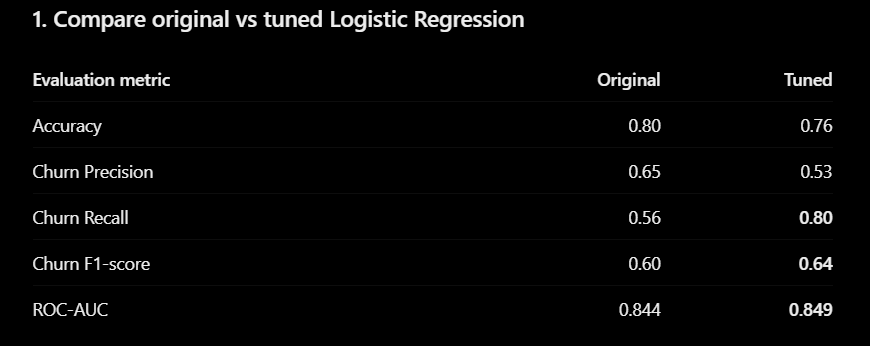

Accuracy decreased from 80% to 76%, and precision decreased from 65% to 53%.

This happens partly because class_weight='balanced' gives more importance to the minority churn class.

**CONCLUSION**

GridSearchCV was used to optimize Logistic Regression using five-fold cross-validation. The best parameters were C = 0.1, class_weight = 'balanced' and solver = 'liblinear'. The tuned model achieved a validation F1-score of 0.64 for the churn class and an ROC-AUC of 0.849. Although accuracy decreased from 80% to 76%, churn recall improved from 56% to 80%. Therefore, the tuned model provides better identification of potential churners, which is an important objective for customer retention.

# **TESTING THE MODEL**

In [140]:
# Prepare the testing data.
# Separate the input features and targets.
X_test = test_raw.drop(columns=['customerID', 'Churn'])

y_test = test_raw['Churn'].map({'No': 0, 'Yes': 1})

In [141]:
# We already created CustomerLifetimeValue and Tenure_Contract in both train_raw and test_raw.
# Check that is present.
print("Testing features:", X_test.shape)
print("Testing target:", y_test.shape)

Testing features: (1409, 21)
Testing target: (1409,)


In [142]:
# Make predictions.
# Use the tuned model selected by GridSearchCV
y_pred_test = best_model.predict(X_test)

In [143]:
# Evaluate the model.
print("Accuracy:", accuracy_score(y_test, y_pred_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

print("ROC-AUC Score:")
print(roc_auc_score(
    y_test,
    best_model.predict_proba(X_test)[:, 1]
))

Accuracy: 0.7224982256919801

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1044
           1       0.48      0.77      0.59       365

    accuracy                           0.72      1409
   macro avg       0.69      0.74      0.69      1409
weighted avg       0.79      0.72      0.74      1409

Confusion Matrix:
[[737 307]
 [ 84 281]]
ROC-AUC Score:
0.8388652705610665


Confusion matrix

- TN – 737: Correctly identified customers who stayed.
- FP – 307: Predicted churn, but customers actually stayed.
- FN – 84: Failed to identify customers who churned.
- TP – 281: Correctly identified customers who churned.
The model identified 281 of the 365 actual churners.



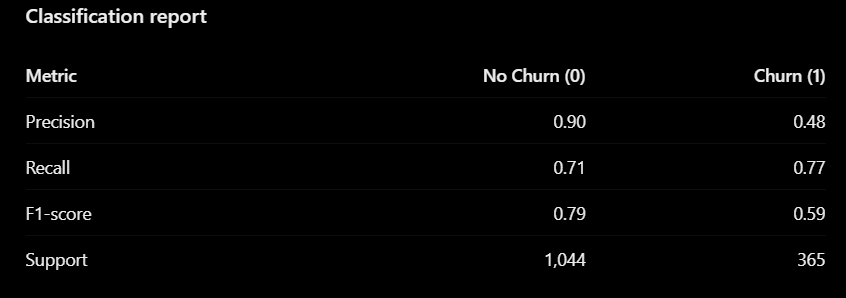

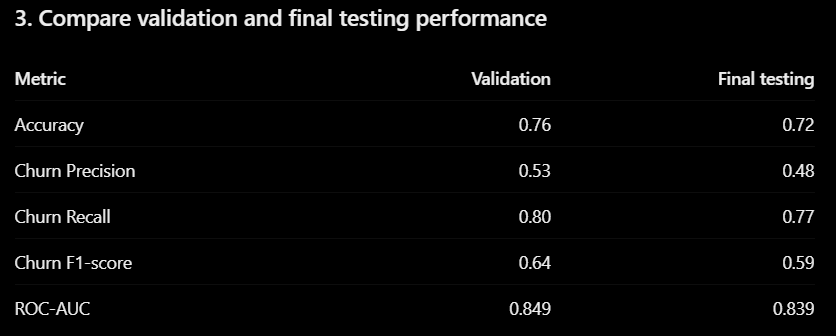

The testing performance is slightly lower than validation performance, which is normal when evaluating on unseen data.

The ROC-AUC scores are relatively close (0.849 and 0.839), suggesting that the model maintains similar class-discrimination ability on the test dataset.

# **Business Recommendations**

Customer retention campaigns: Contact customers identified as potential churners and offer appropriate retention incentives.



Prioritize high-risk customers: Since false positives are relatively high, prioritize customers with the highest predicted churn probabilities rather than treating every flagged customer equally.



Review customer contracts and services: Investigate patterns associated with contract types, tenure, payment methods and monthly charges to identify opportunities to improve retention.

# **FINAL CONCLUSION**

This project focused on predicting customer churn using machine learning classification techniques.

During exploratory data analysis, customer distributions, missing values, relationships between features and churn, and potential outliers were examined. Data preprocessing included missing-value imputation, categorical encoding and numerical scaling.

Feature engineering was performed by creating CustomerLifetimeValue and Tenure_Contract. Random Forest feature importance was used to identify relevant features.

Three classification algorithms were developed and evaluated: Logistic Regression, Decision Tree and Random Forest. Logistic Regression achieved the best overall validation performance, with an accuracy of approximately 80% and ROC-AUC of 0.844.

Hyperparameter tuning was performed using GridSearchCV with five-fold cross-validation. The selected parameters were C = 0.1, class_weight = 'balanced' and solver = 'liblinear'.

The tuned model achieved the following final testing results:

- Accuracy: 72.25%
- Churn Precision: 48%
- Churn Recall: 77%
- Churn F1-score: 0.59
- ROC-AUC: 0.839

The model successfully identified a substantial proportion of customers who actually churned. However, its relatively low precision indicates that some customers predicted as potential churners did not actually leave.

The model can help telecom companies identify customers at risk of leaving and develop targeted customer retention strategies.